In [212]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [213]:
train_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/train_dataset.csv")
test_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/test_without_gt.csv")
submission_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/submission_template_for_test.csv")

In [214]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

In [215]:
train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [216]:
test_data

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211850001,20,1,1,301,301,640,1,1,1,...,200000,1,0,1,0,0,1,1,1,0
1,211850002,20,1,2,274,15,640,5,1,1,...,200000,1,40000,1,1,1,0,1,1,0
2,211850003,20,1,2,771,28,640,99,4,1,...,500000,4,50000,0,0,0,0,1,1,1
3,211870001,17,1,2,370,26,640,5,1,1,...,200000,4,54000,0,1,1,0,1,1,1
4,211880001,17,2,1,270,1,540,1,5,1,...,150000,4,48000,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,215490262,20,1,1,268,3,540,99,1,1,...,200000,4,1000,0,0,0,0,1,1,0
137087,215490263,17,1,2,604,187,740,9,1,1,...,50000,1,90000,1,4,2,1,1,1,1
137088,215490264,20,1,1,496,70,440,8,1,1,...,200000,1,0,3,0,0,1,1,1,0
137089,215490265,18,1,1,409,409,240,1,1,1,...,200000,1,0,3,0,0,1,1,1,1


In [217]:
submission_data

,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,0
4,211880001,0
...,...,...
137086,215490262,0
137087,215490263,0
137088,215490264,0
137089,215490265,0


##

## Data preprocessing

In [218]:
Factors_train_data = train_data.copy()

In [219]:
Factors_train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


#### Checking missing value data

In [220]:
Factors_train_data.isna().sum()

ID                                 0
12-Month Default Flag              0
Application Channel                0
Gender                             0
Marital Status                     0
Age (in months)                    0
Residence Period (in months)       0
Occupation Category                0
Industry Category                  0
Employment Type Category           0
Insurance Type                     0
Company Size Category              0
Business Entity Type               0
Declared Annual Income             0
Payday                             0
Declared Number of Borrowings      0
Declared Borrowing Amount          0
Desired Credit Limit               0
Residence Type                     0
Rent Burden                        0
Residence Ownership Status         0
Number of Dependents               0
Number of Dependent Children       0
Home Phone Number Available        0
Mobile Phone Number Available      0
Employer Phone Number Available    0
Driver Licence Number Available    0
d

##

##

##

## Data Analysis

In [221]:
# Dataset overview
print("Shape:", Factors_train_data.shape)

# Data types
Factors_train_data.info()

# Statistical summary
display(Factors_train_data.describe().T)

# First 5 rows
display(Factors_train_data.head())

Shape: (68546, 27)
<class 'pandas.DataFrame'>
RangeIndex: 68546 entries, 0 to 68545
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   ID                               68546 non-null  int64
 1   12-Month Default Flag            68546 non-null  int64
 2   Application Channel              68546 non-null  int64
 3   Gender                           68546 non-null  int64
 4   Marital Status                   68546 non-null  int64
 5   Age (in months)                  68546 non-null  int64
 6   Residence Period (in months)     68546 non-null  int64
 7   Occupation Category              68546 non-null  int64
 8   Industry Category                68546 non-null  int64
 9   Employment Type Category         68546 non-null  int64
 10  Insurance Type                   68546 non-null  int64
 11  Company Size Category            68546 non-null  int64
 12  Business Entity Type             68546

,count,mean,std,min,25%,50%,75%,max
ID,68546.0,2.136238e+08,1.017470e+06,211850010.0,2.127305e+08,213570122.5,214510033.5,2.154903e+08
12-Month Default Flag,68546.0,9.676713e-02,2.956426e-01,0.0,0.000000e+00,0.0,0.0,1.000000e+00
Application Channel,68546.0,1.697823e+01,4.630383e+00,1.0,1.700000e+01,18.0,20.0,2.000000e+01
Gender,68546.0,1.312316e+00,4.634412e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Marital Status,68546.0,1.311324e+00,4.630382e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Age (in months),68546.0,4.153405e+02,1.530383e+02,234.0,2.820000e+02,368.0,530.0,8.400000e+02
Residence Period (in months),68546.0,1.301110e+02,1.355671e+02,0.0,2.300000e+01,77.0,214.0,8.380000e+02
Occupation Category,68546.0,6.315283e+02,3.241452e+02,140.0,5.400000e+02,640.0,640.0,1.540000e+03
Industry Category,68546.0,3.433815e+01,4.184968e+01,1.0,5.000000e+00,9.0,99.0,9.900000e+01
Employment Type Category,68546.0,2.539754e+00,2.014826e+00,1.0,1.000000e+00,1.0,5.0,8.000000e+00


,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1


#### Outlier

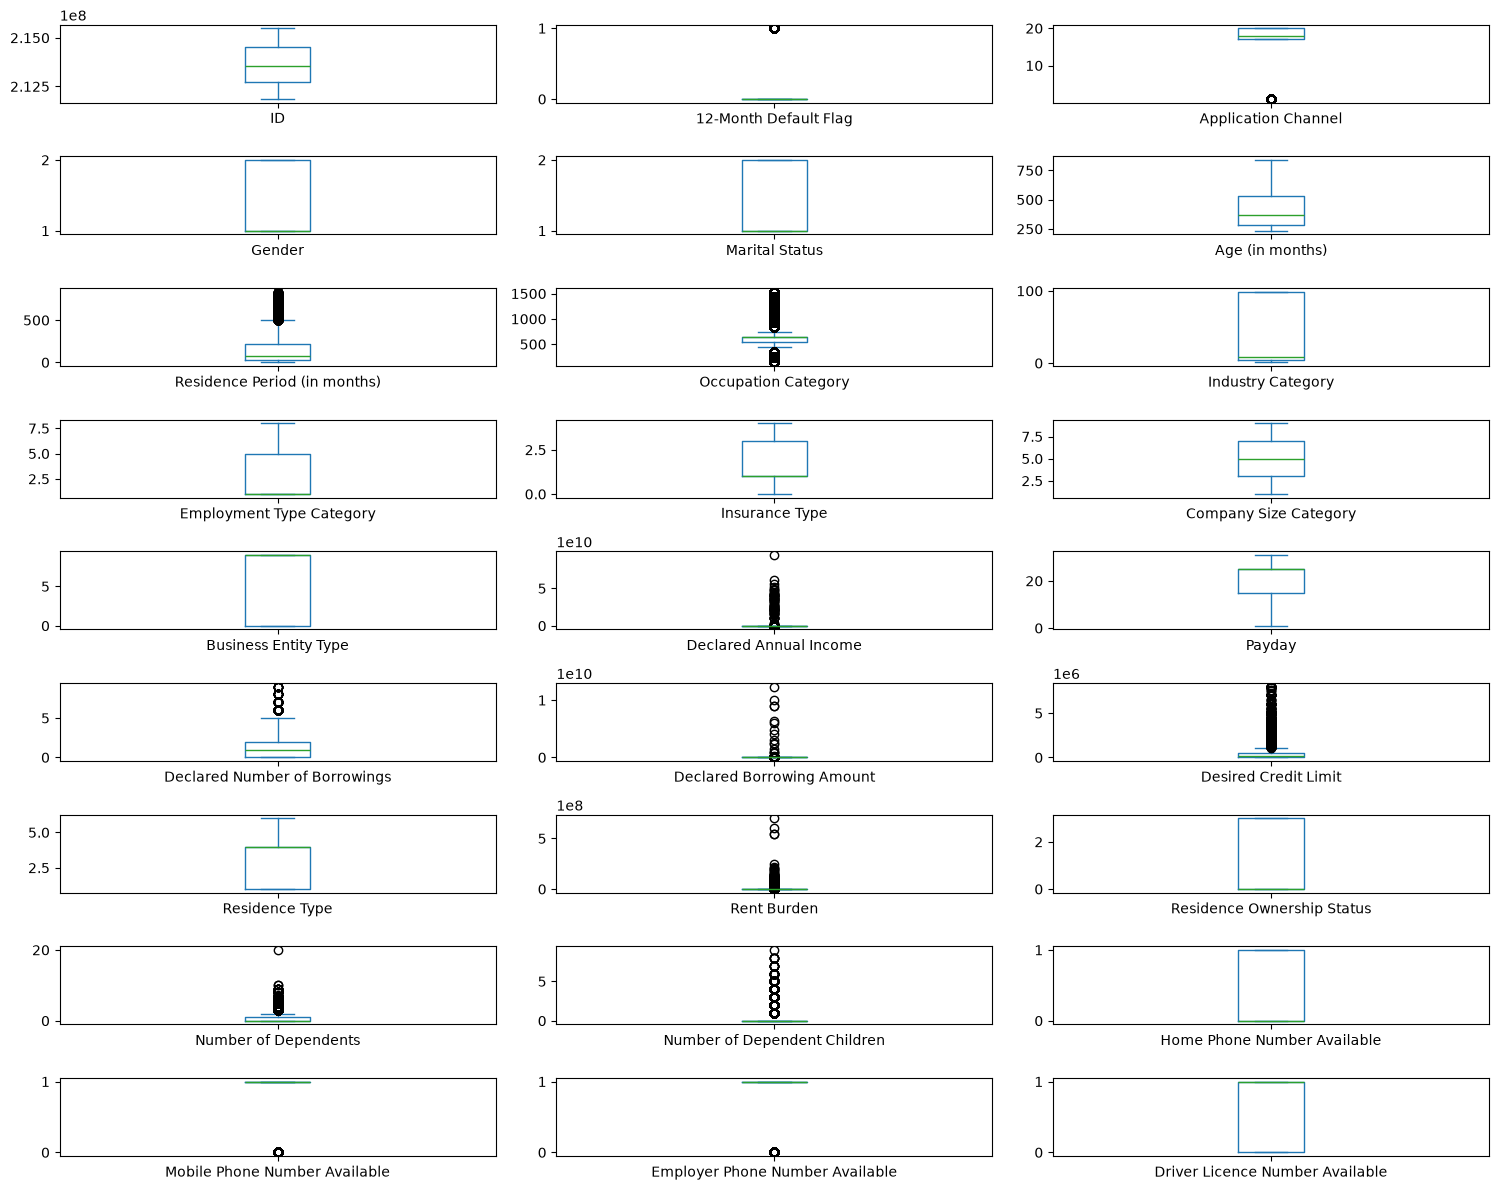

In [222]:
Factors_train_data.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

#### Class Imbalance


In [223]:
target = '12-Month Default Flag'

# Count
print(Factors_train_data[target].value_counts())

# Percentage
print(Factors_train_data[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0    61913
1     6633
Name: count, dtype: int64
12-Month Default Flag
0    90.323287
1     9.676713
Name: proportion, dtype: float64


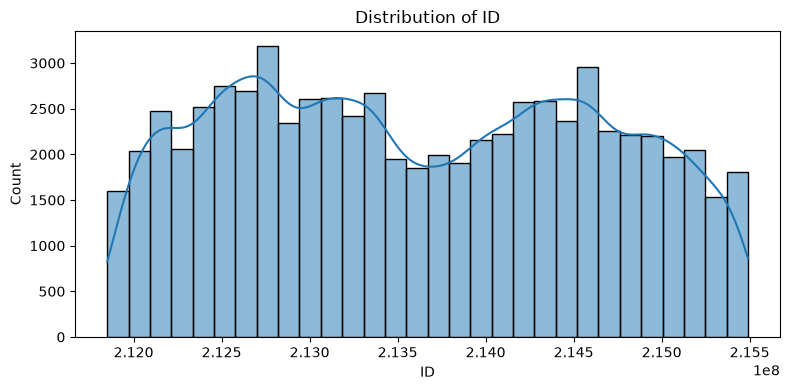

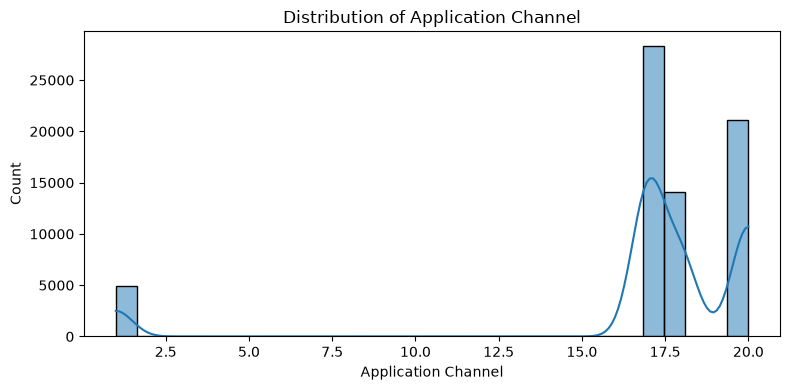

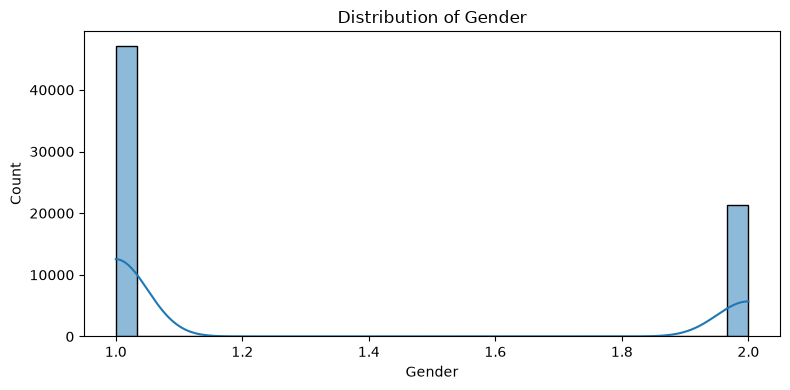

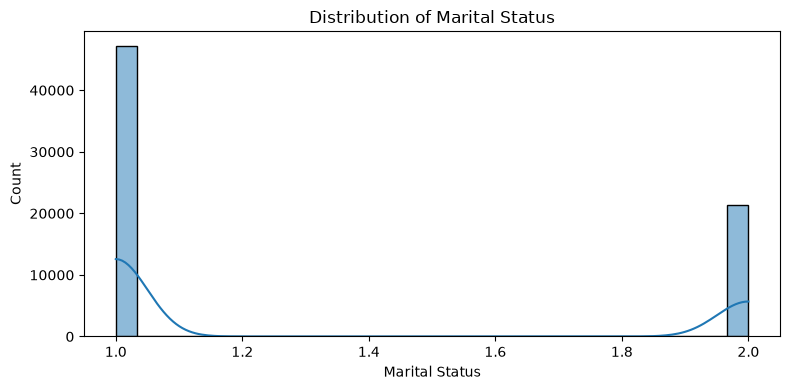

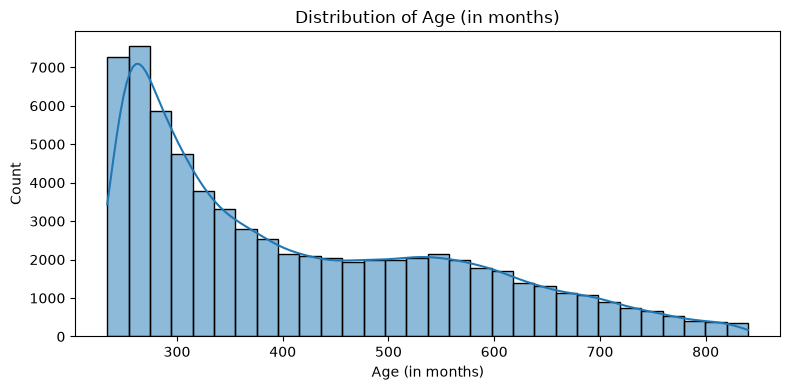

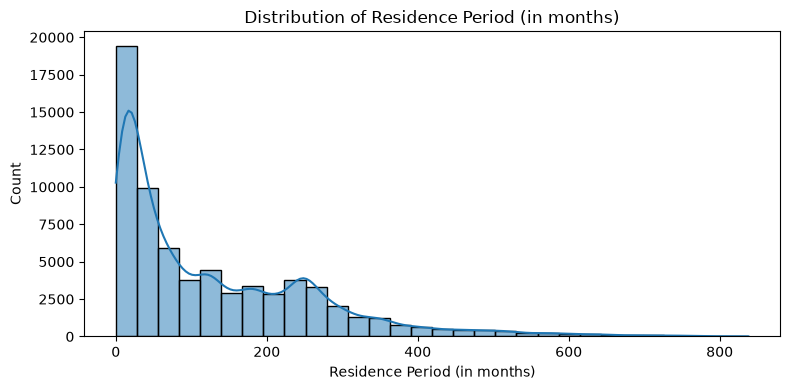

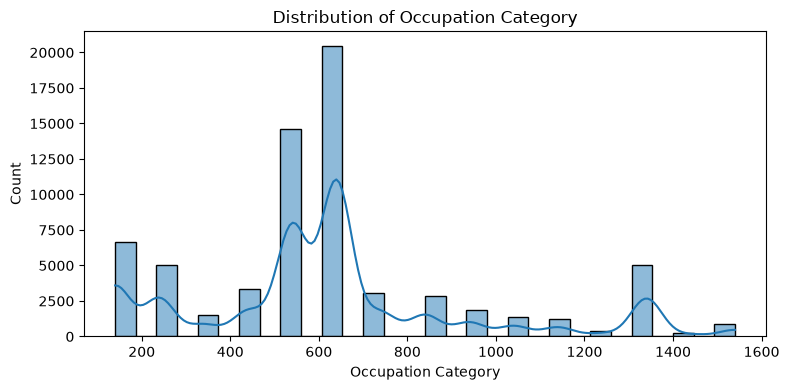

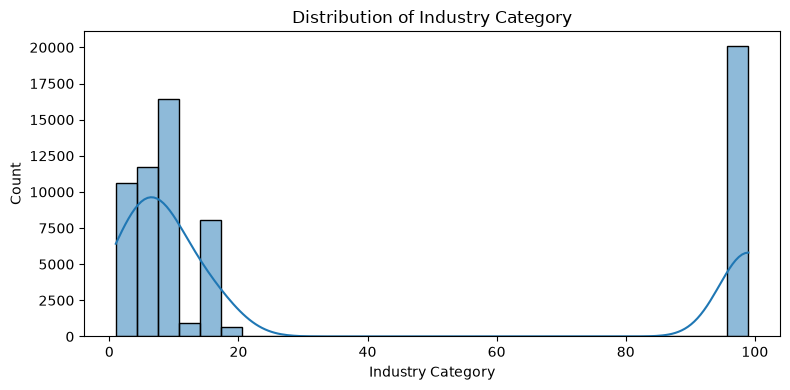

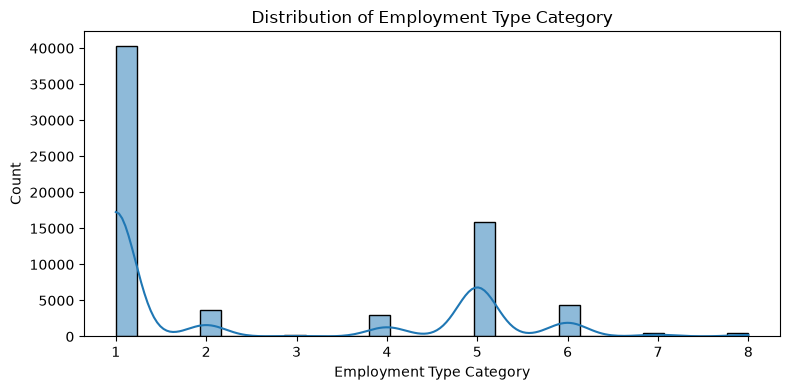

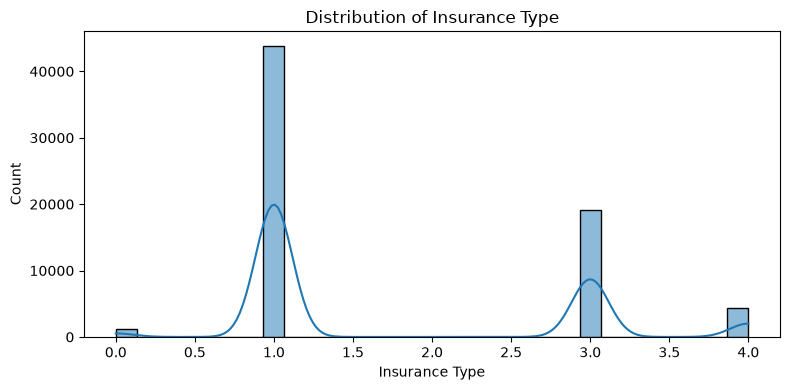

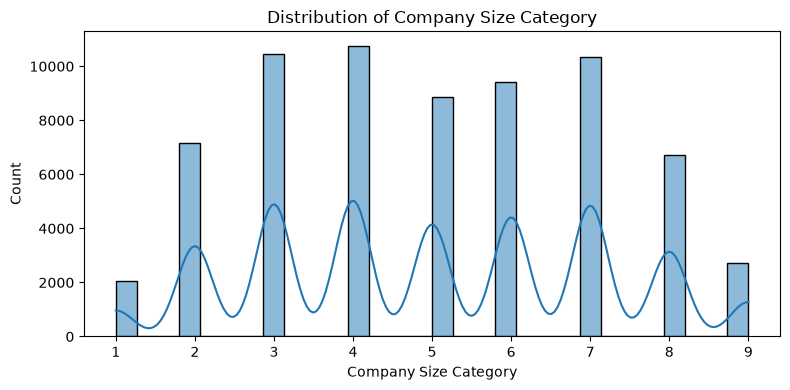

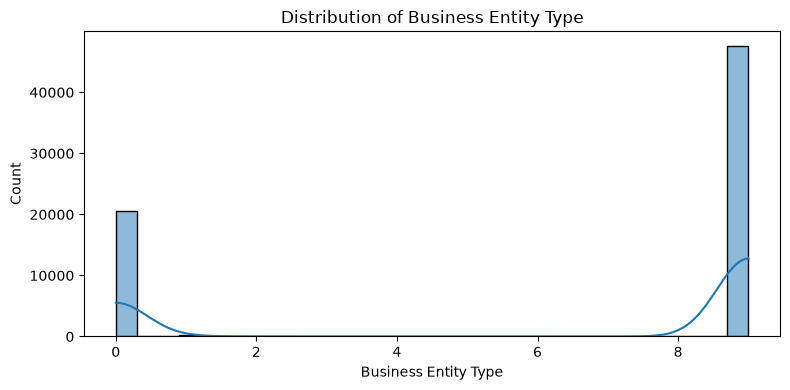

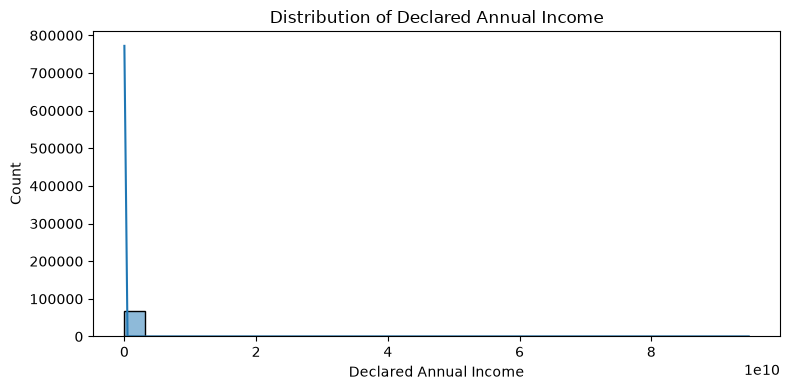

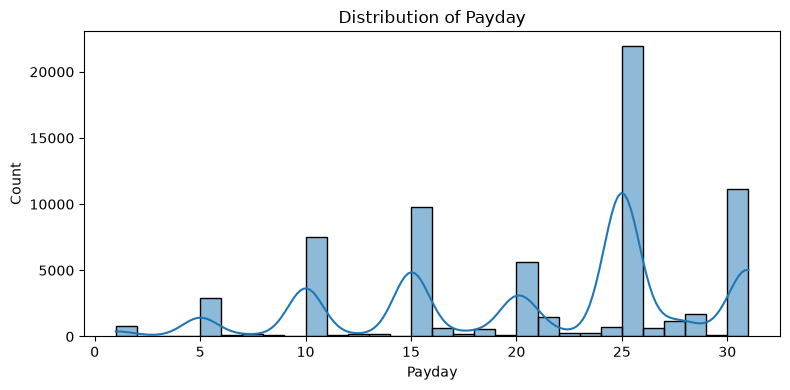

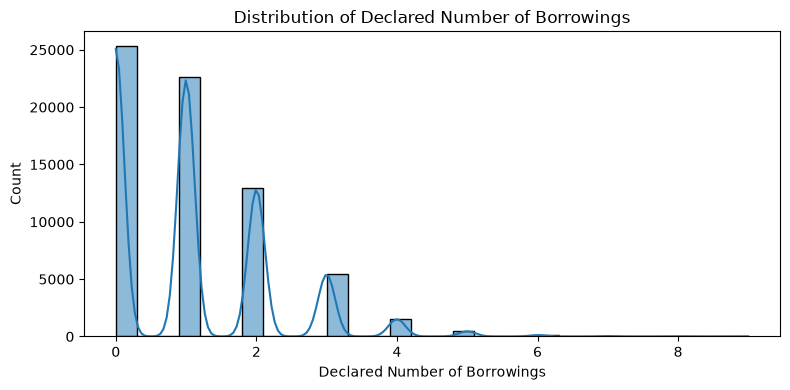

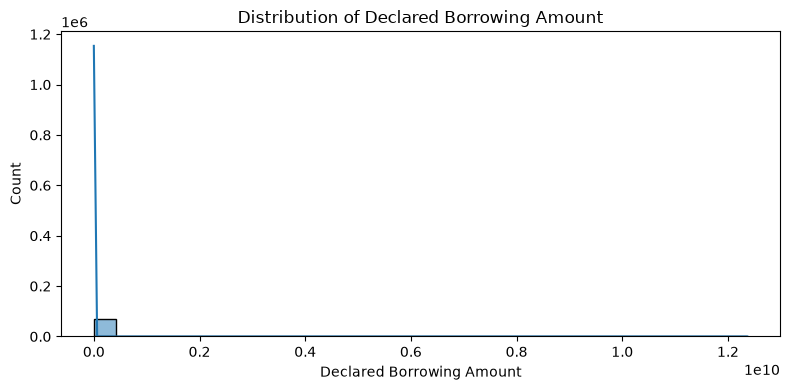

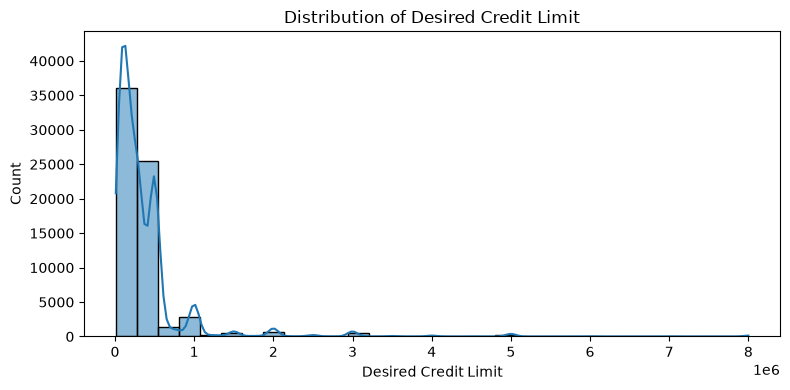

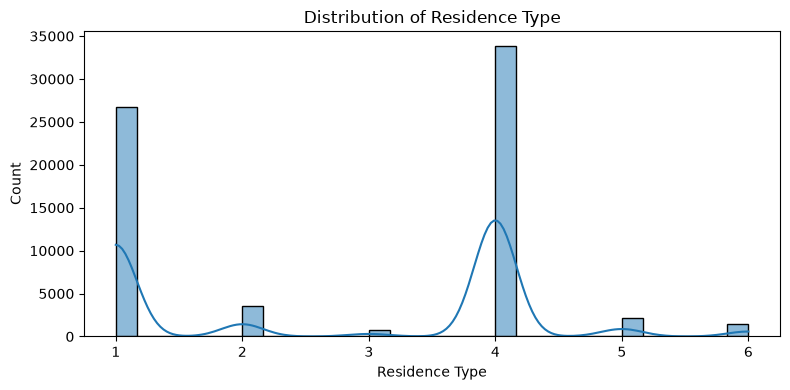

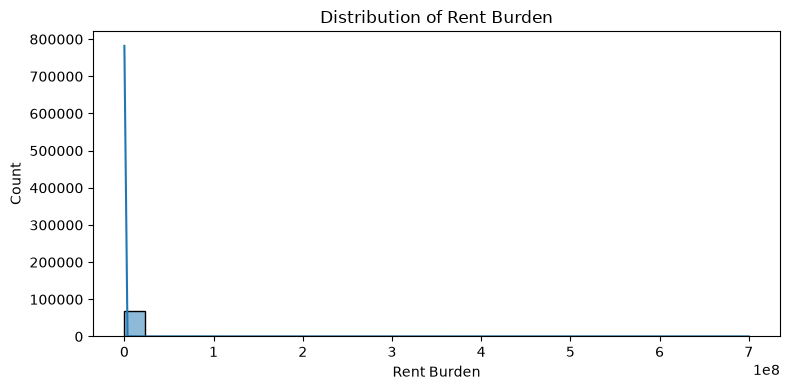

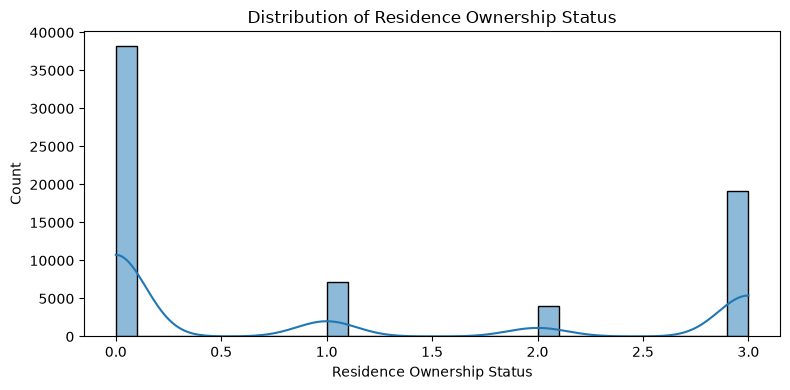

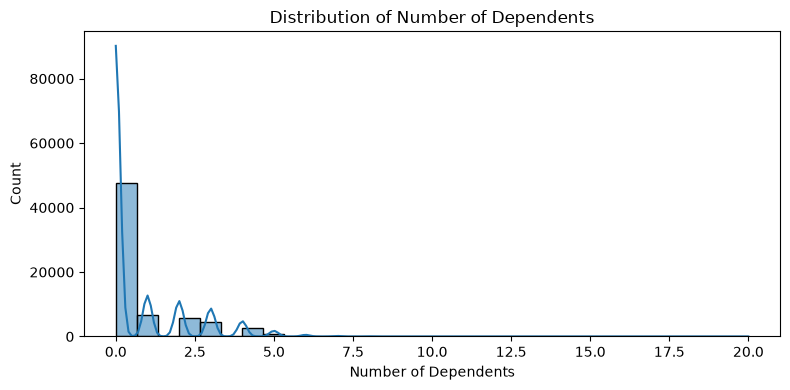

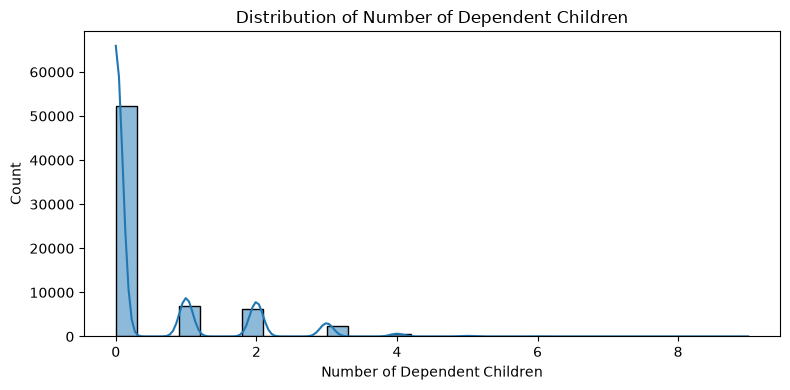

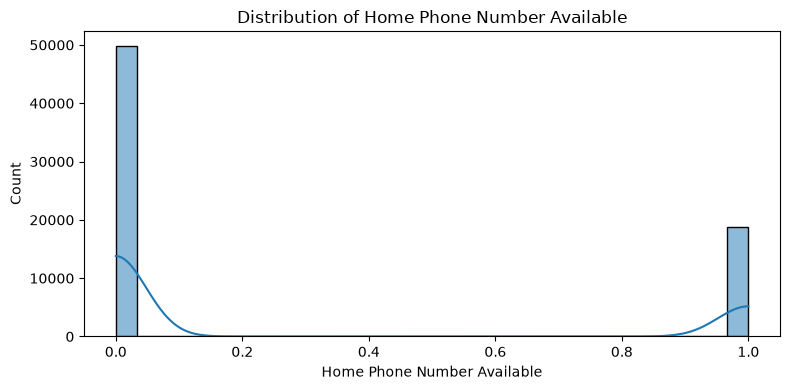

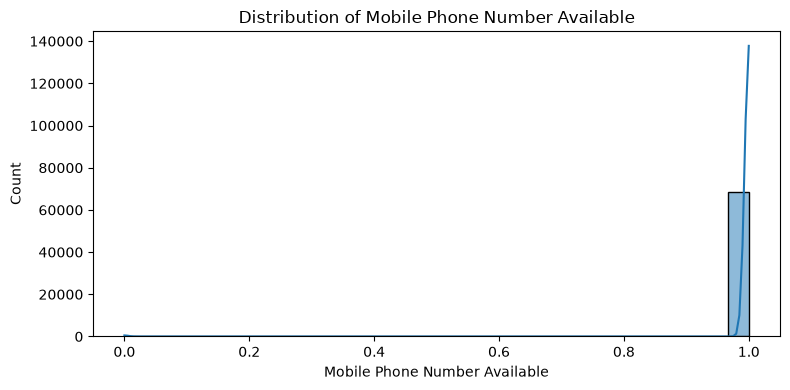

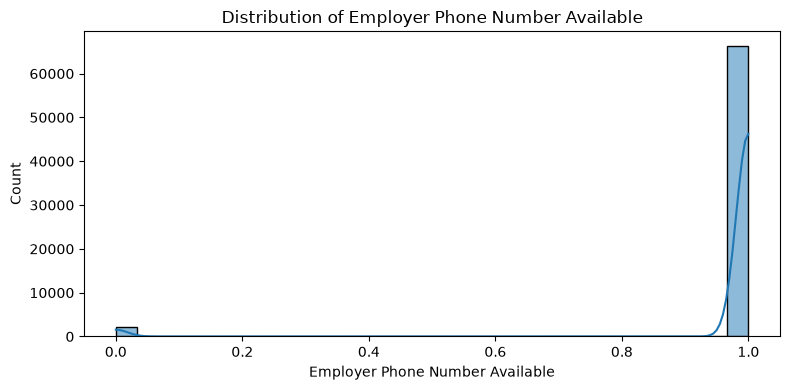

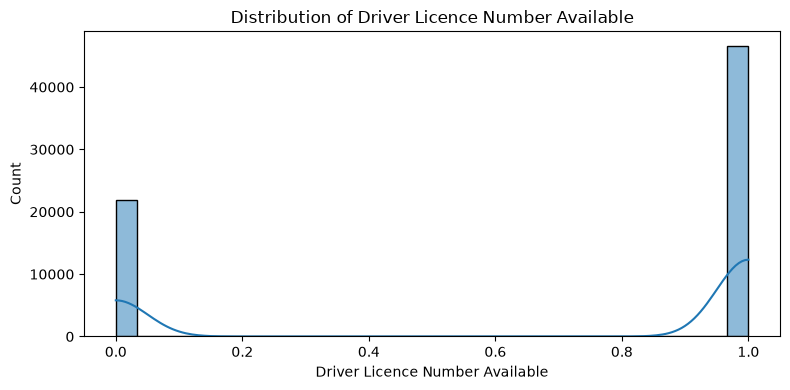

In [224]:
numeric_cols = Factors_train_data.select_dtypes(
    include='number'
).columns.drop(target, errors='ignore')

for col in numeric_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=Factors_train_data,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

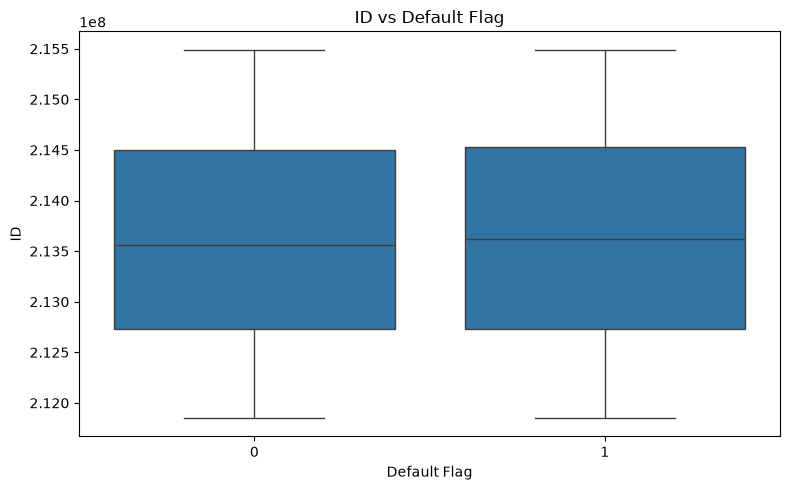

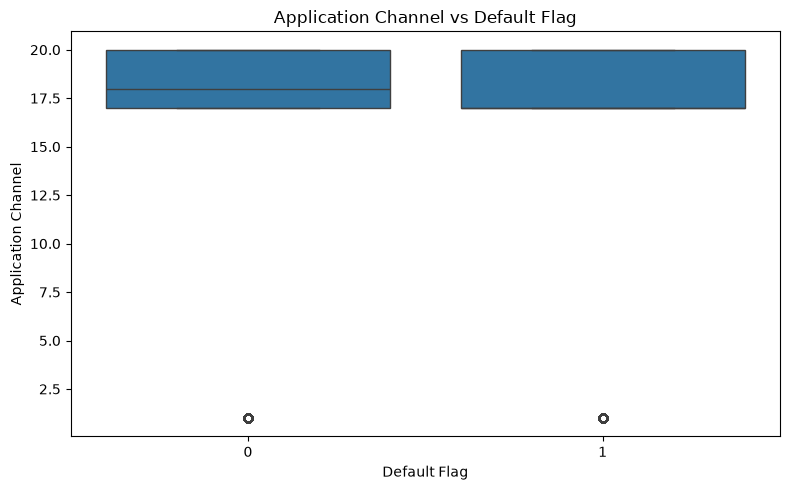

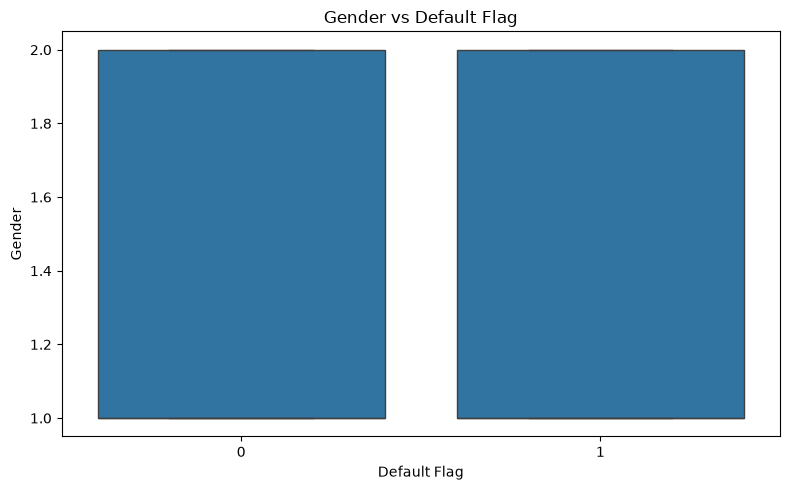

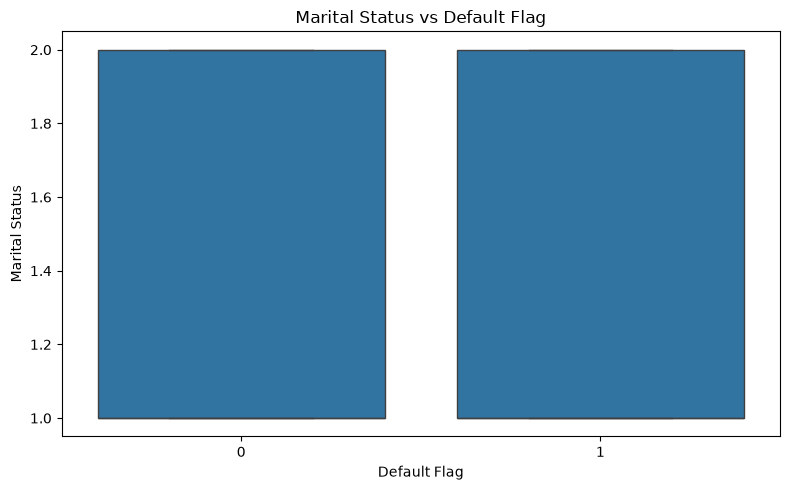

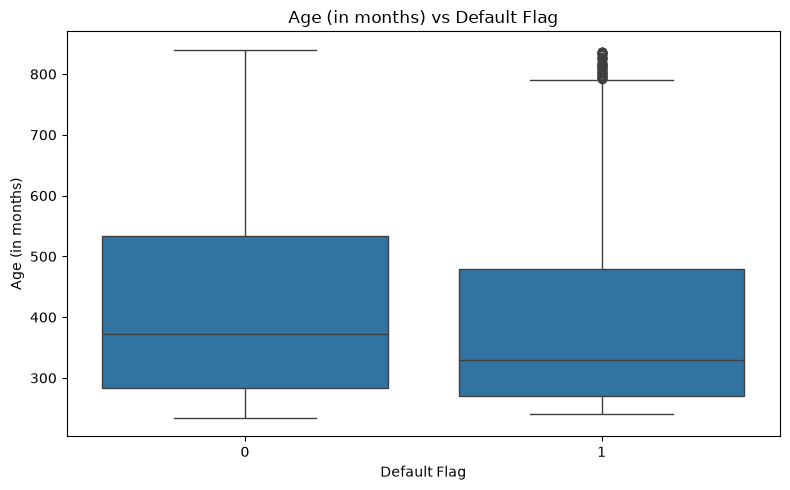

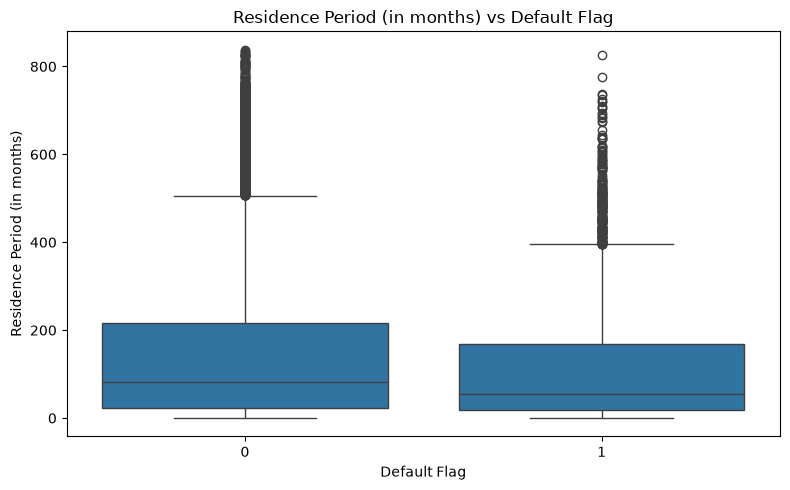

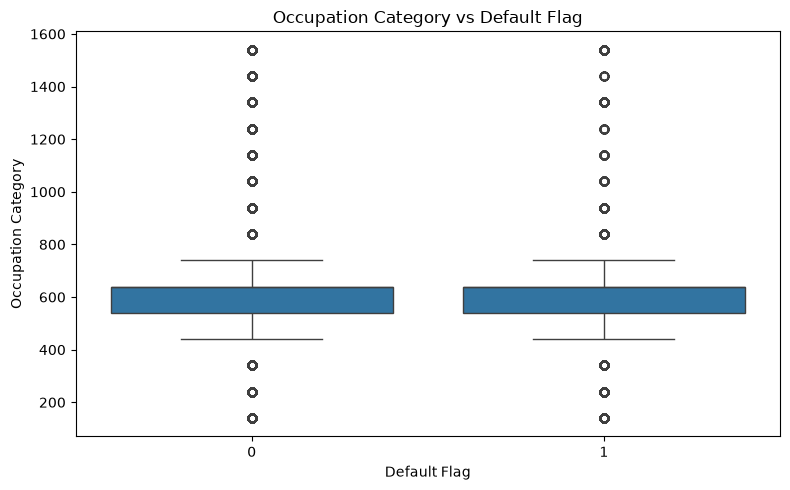

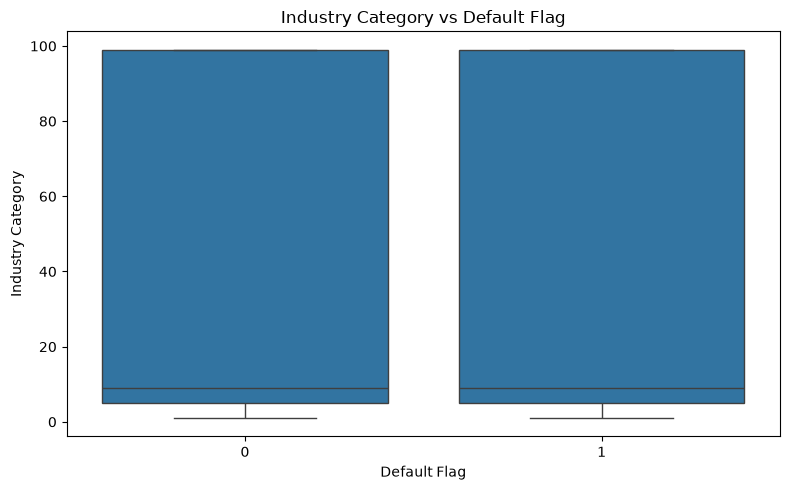

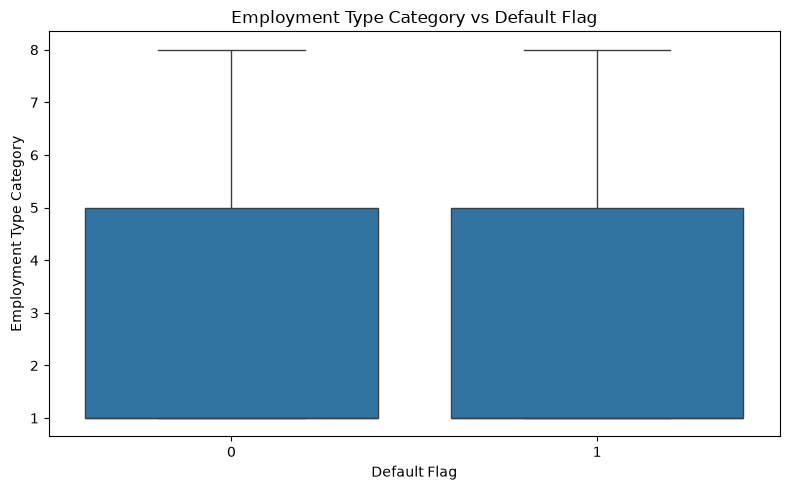

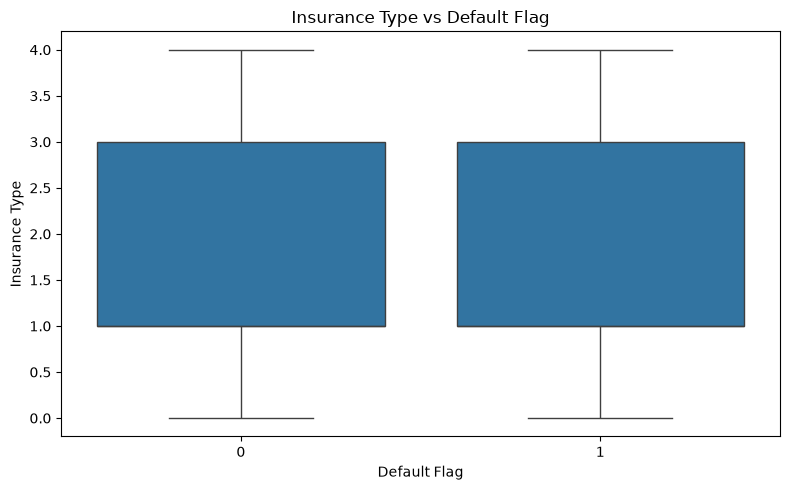

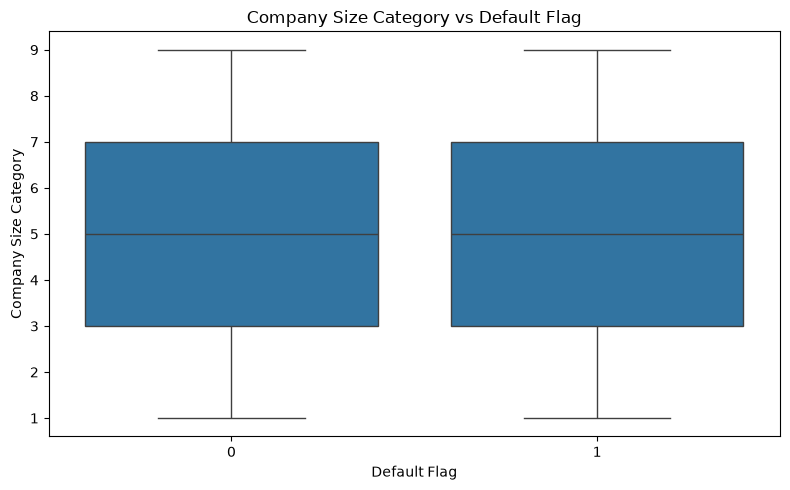

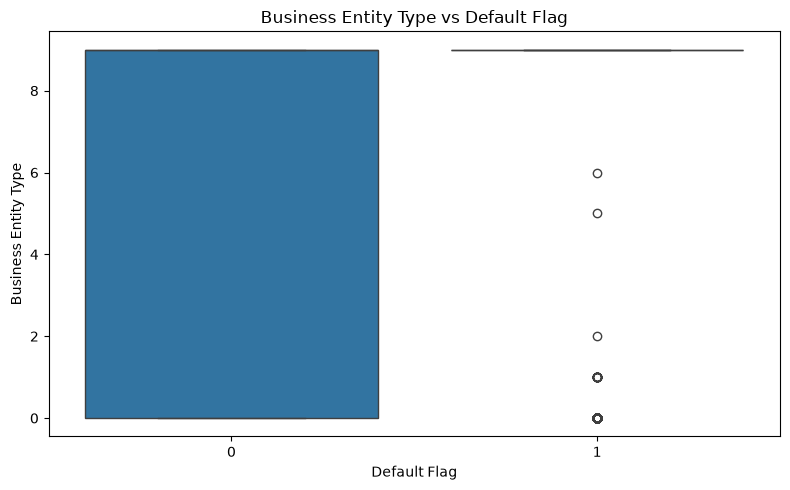

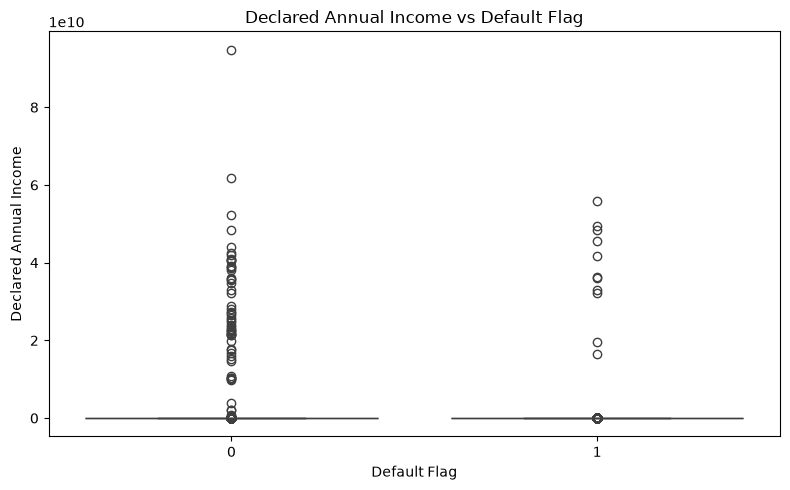

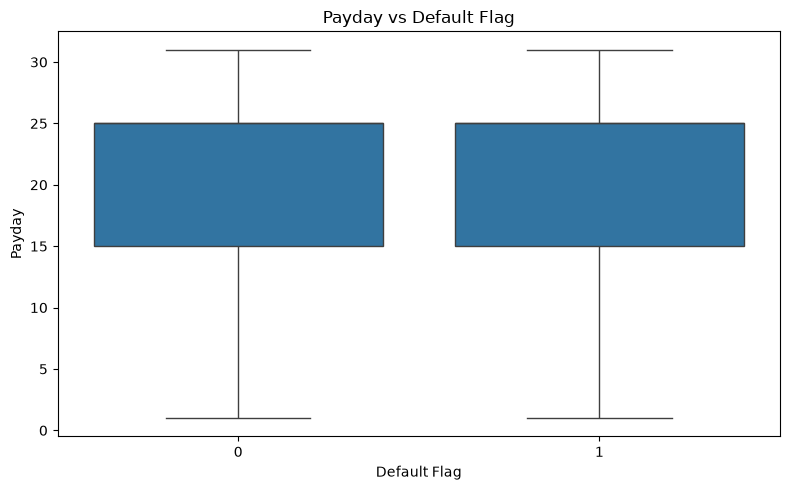

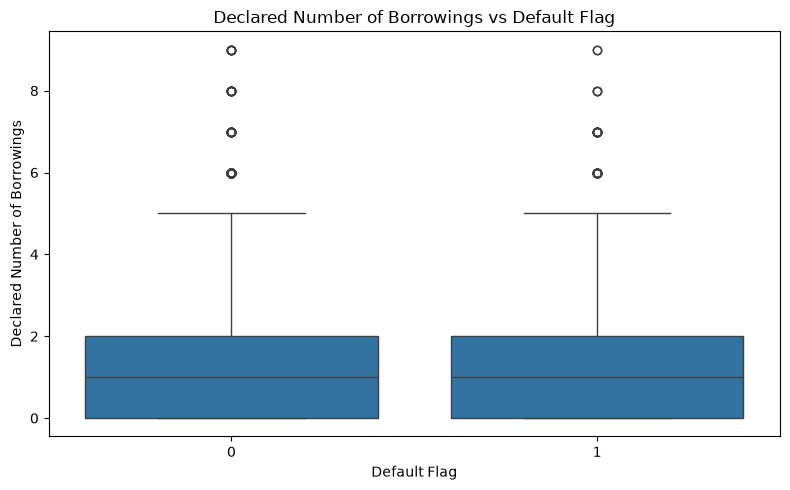

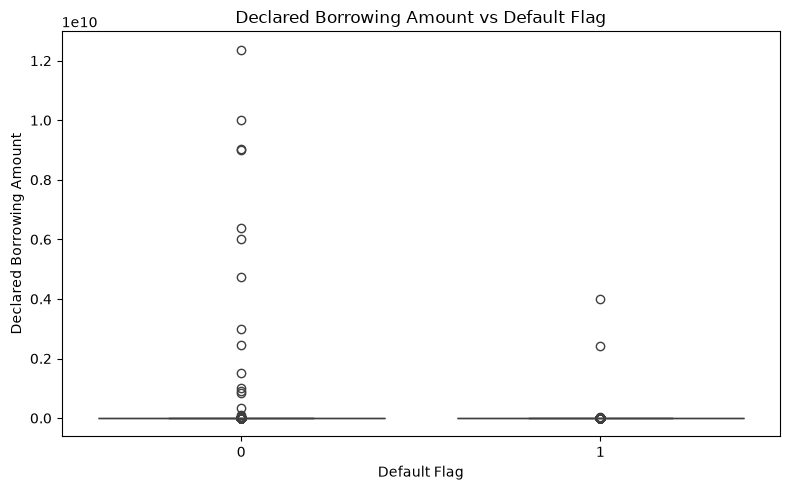

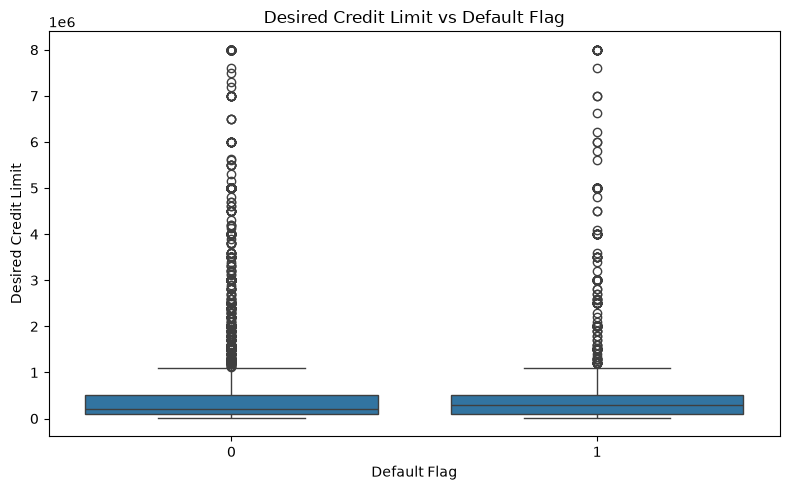

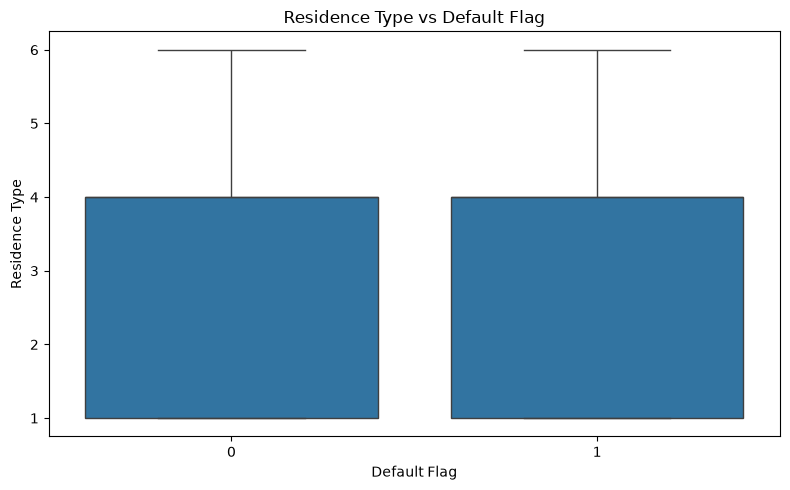

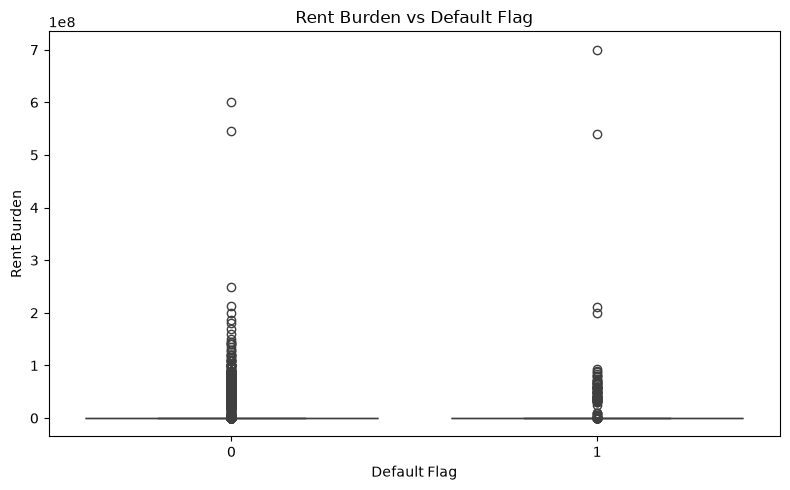

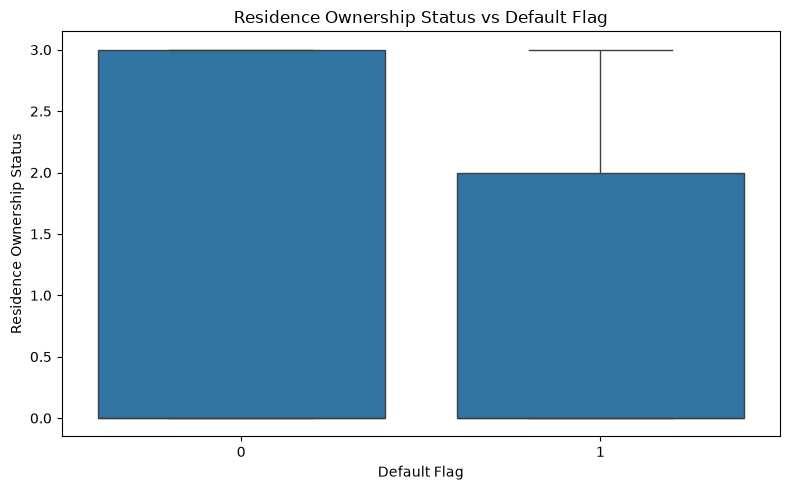

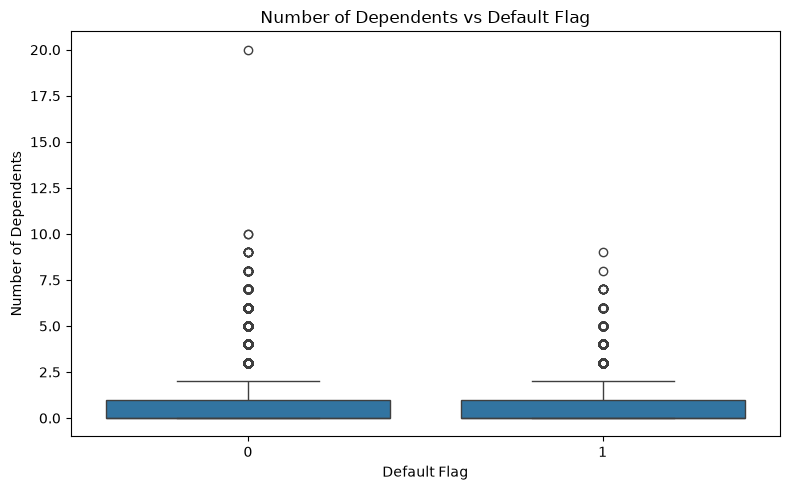

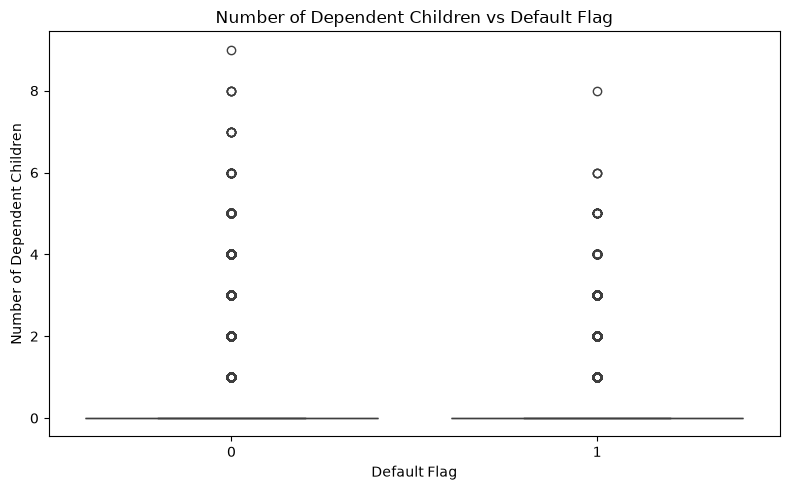

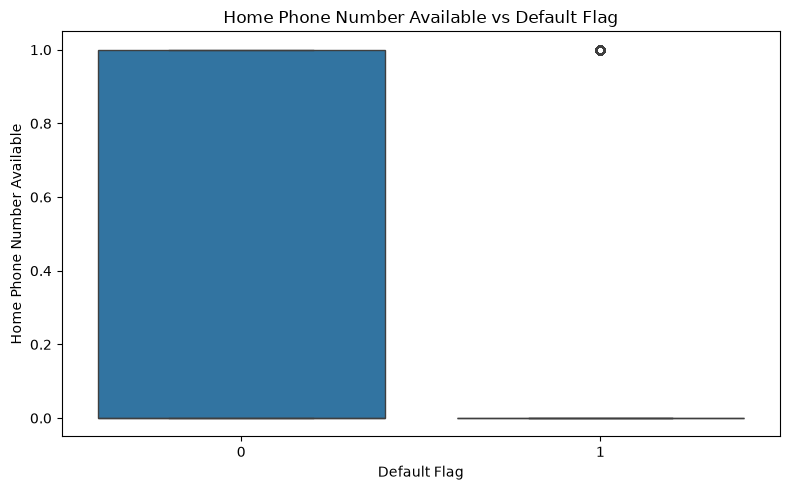

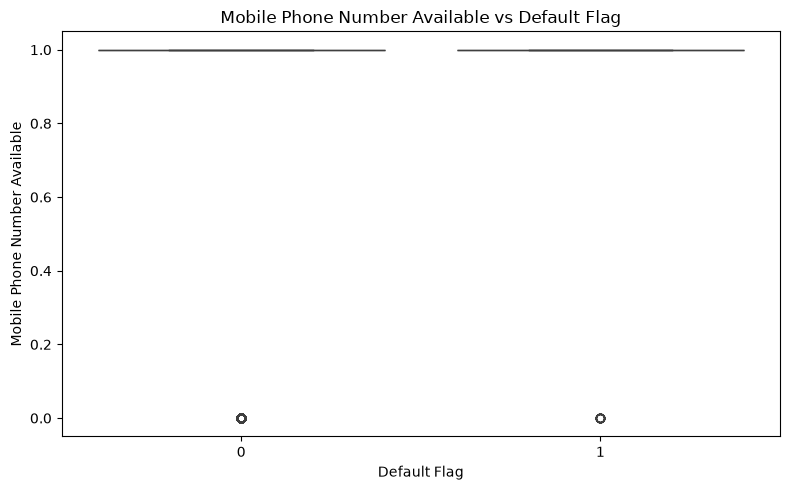

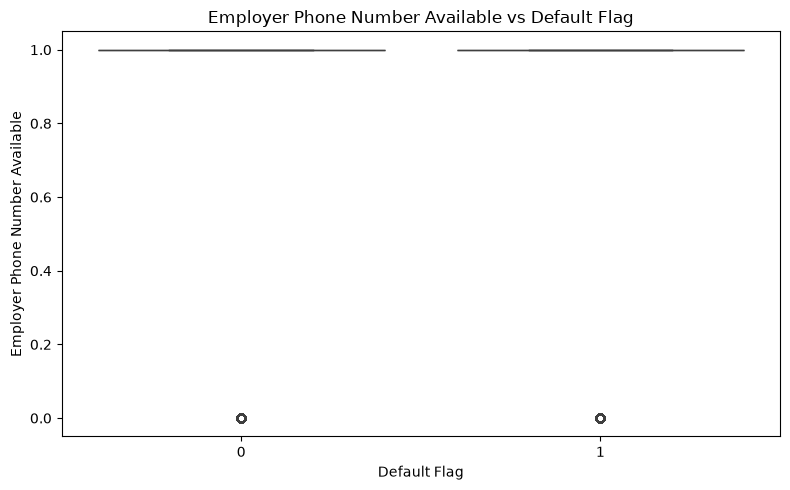

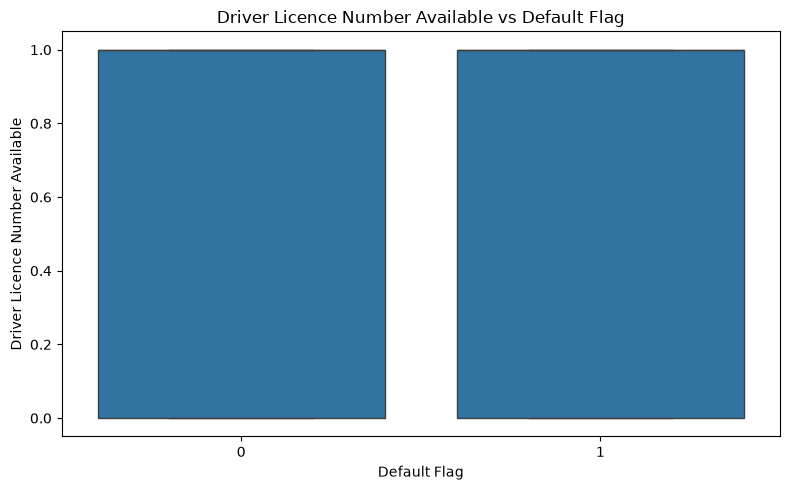

In [225]:
for col in numeric_cols:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=Factors_train_data,
        x=target,
        y=col
    )

    plt.title(f"{col} vs Default Flag")
    plt.xlabel("Default Flag")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

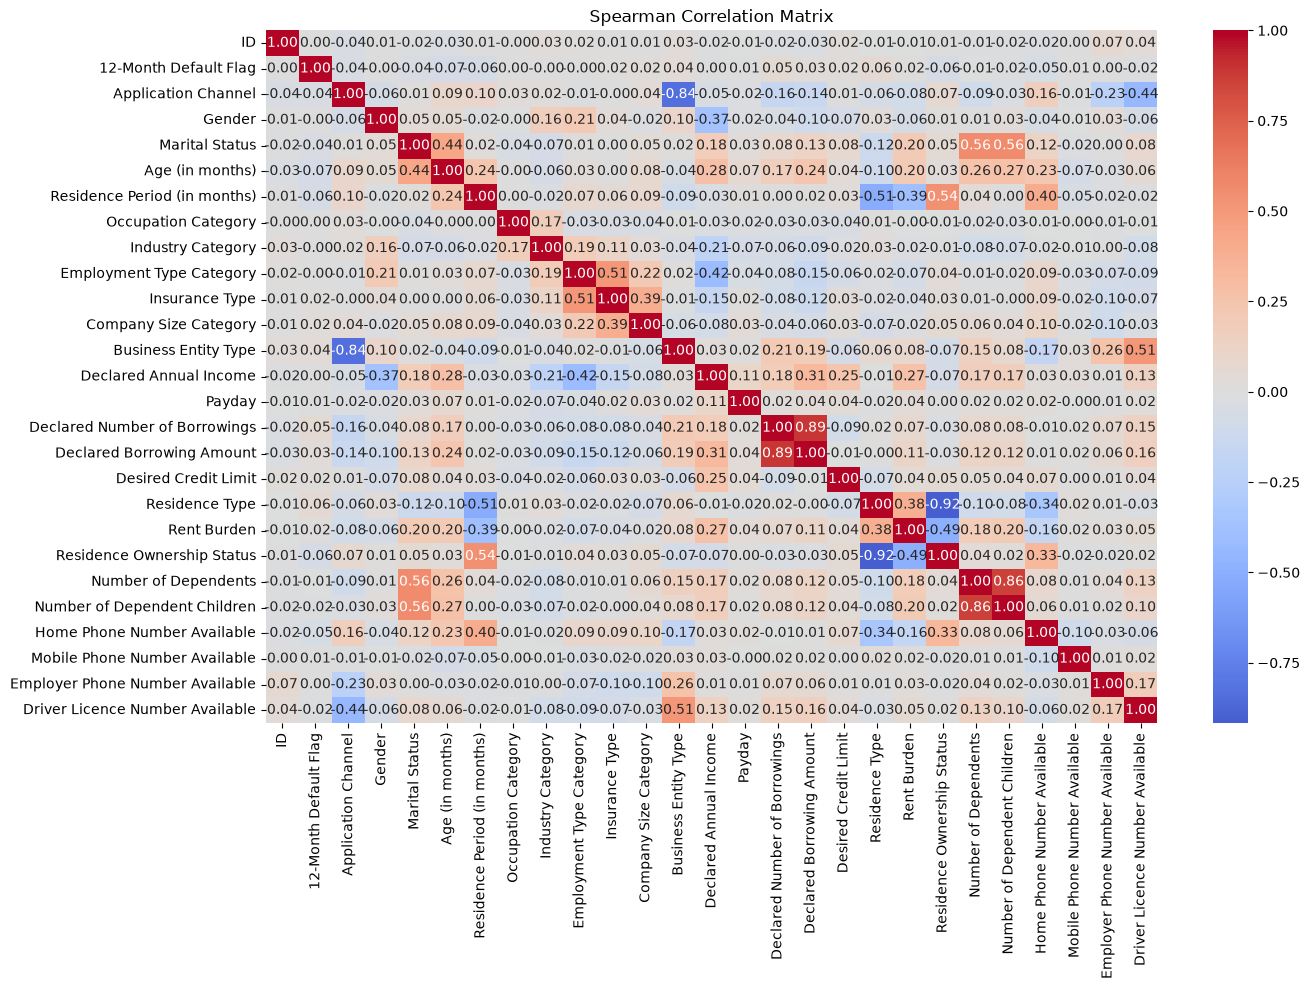

In [226]:
corr = Factors_train_data.select_dtypes(
    include='number'
).corr(method='spearman')

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

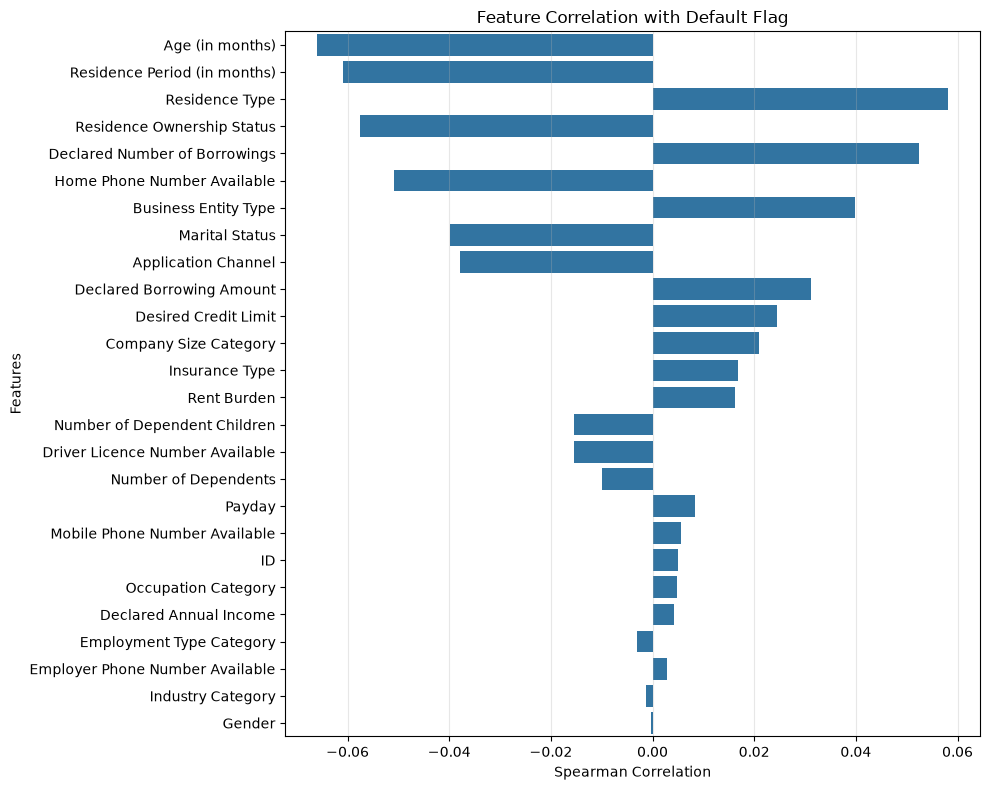

In [227]:
target_corr = (
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Feature Correlation with Default Flag")
plt.xlabel("Spearman Correlation")
plt.ylabel("Features")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

##

##

## Modeling

In [228]:
# Normalie
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

In [229]:
Factors_train_data.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [230]:
factors_train = Factors_train_data[["Residence Type", 
                                    "Declared Number of Borrowings", 
                                    "Business Entity Type", 
                                    "Declared Borrowing Amount", 
                                    "Desired Credit Limit", 
                                    "Company Size Category", 
                                    "Insurance Type",
                                    "Rent Burden",
                                    "Payday",
                                    "Mobile Phone Number Available",
                                    "Employer Phone Number Available",
                                    "Occupation Category",
                                    "Declared Annual Income",
                                ]]
factors_target = Factors_train_data[["12-Month Default Flag"]]

In [231]:
factors_train

,Residence Type,Declared Number of Borrowings,Business Entity Type,Declared Borrowing Amount,Desired Credit Limit,Company Size Category,Insurance Type,Rent Burden,Payday,Mobile Phone Number Available,Employer Phone Number Available,Occupation Category,Declared Annual Income
0,1,3,9,1400000,300000,8,4,50000,10,1,1,140,4800000
1,3,4,0,600000,200000,3,3,0,25,1,0,640,3500000
2,1,1,9,180000,100000,6,1,0,15,1,1,540,1560000
3,1,2,9,500000,100000,5,3,0,12,1,1,640,1800000
4,4,1,9,1000000,100000,5,1,60000,21,1,1,1040,5000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,1,1,9,100000,200000,6,3,0,21,1,1,640,3600000
68542,5,0,9,0,50000,6,3,53000,20,1,1,640,2500000
68543,1,2,9,1700000,300000,7,1,0,25,1,1,340,6000000
68544,2,1,0,100000,50000,5,1,0,25,1,0,640,2040000


In [232]:
factors_target

,12-Month Default Flag
0,0
1,0
2,0
3,0
4,1
...,...
68541,0
68542,0
68543,0
68544,0


In [233]:
factors_train = np.array(factors_train)
factors_target = factors_target.values.ravel() # Flatten the target array to 1D

In [234]:
## Normalization and Train-Test Split
scaler_x = StandardScaler()
factors_train_scaled = scaler_x.fit_transform(factors_train)

In [235]:
factors_train_scaled

array([[-1.15961211,  1.70399274,  0.66262573, ...,  0.18278051,
        -1.51639423, -0.02612666],
       [ 0.13696683,  2.59478061, -1.51338442, ..., -5.47104291,
         0.02613565, -0.02738139],
       [-1.15961211, -0.07758299,  0.66262573, ...,  0.18278051,
        -0.28237033, -0.02925382],
       ...,
       [-1.15961211,  0.81320488,  0.66262573, ...,  0.18278051,
        -0.89938228, -0.02496846],
       [-0.51132264, -0.07758299, -1.51338442, ..., -5.47104291,
         0.02613565, -0.02879054],
       [-1.15961211, -0.96837085, -1.51338442, ...,  0.18278051,
         0.02613565, -0.02786397]], shape=(68546, 13))

In [236]:
X_train_svm, y_train_svm = factors_train_scaled, factors_target
X_train_svm.shape, y_train_svm.shape

((68546, 13), (68546,))

In [237]:
## Train-Test split
x_train_split, x_test_split, y_train_split, y_test_split = train_test_split(factors_train_scaled, y_train_svm, test_size=0.2, random_state=42)

In [238]:
x_train_split.shape, x_test_split.shape, y_train_split.shape, y_test_split.shape

((54836, 13), (13710, 13), (54836,), (13710,))

In [239]:
## Model Training 
clf = SVC()
clf.fit(x_train_split, y_train_split)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [240]:
## Evaluation
clf.predict(x_test_split)

array([0, 0, 0, ..., 0, 0, 0], shape=(13710,))

In [241]:
def evaluate_model(y_true, y_pred, y_prob=None):

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    }

    display(pd.DataFrame(
        metrics.items(),
        columns=["Metric", "Score"]
    ))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    return metrics

,Metric,Score
0,Accuracy,0.904887
1,Precision,0.000000
2,Recall,0.000000
3,F1-score,0.000000


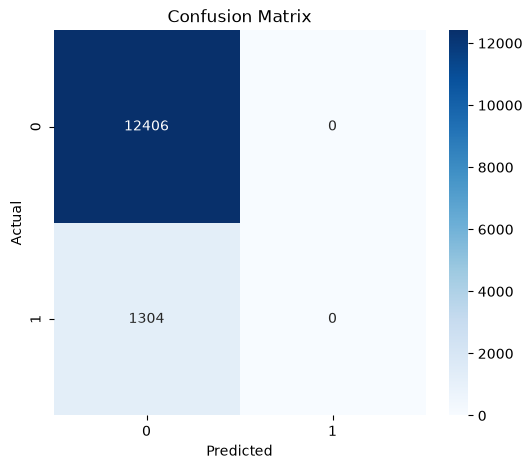

              precision    recall  f1-score   support

           0       0.90      1.00      0.95     12406
           1       0.00      0.00      0.00      1304

    accuracy                           0.90     13710
   macro avg       0.45      0.50      0.48     13710
weighted avg       0.82      0.90      0.86     13710



{'Accuracy': 0.9048869438366156,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1-score': 0.0}

In [242]:
evaluate_model(y_test_split, clf.predict(x_test_split))

##

## Test set

In [243]:
factors_test_svm = test_data[["Residence Type", 
                                    "Declared Number of Borrowings", 
                                    "Business Entity Type", 
                                    "Declared Borrowing Amount", 
                                    "Desired Credit Limit", 
                                    "Company Size Category", 
                                    "Insurance Type",
                                    "Rent Burden",
                                    "Payday",
                                    "Mobile Phone Number Available",
                                    "Employer Phone Number Available",
                                    "Occupation Category",
                                    "Declared Annual Income",
                                ]]

In [244]:
factors_test_svm

,Residence Type,Declared Number of Borrowings,Business Entity Type,Declared Borrowing Amount,Desired Credit Limit,Company Size Category,Insurance Type,Rent Burden,Payday,Mobile Phone Number Available,Employer Phone Number Available,Occupation Category,Declared Annual Income
0,1,0,0,0,200000,3,1,0,10,1,1,640,3000000
1,1,0,0,0,200000,5,1,40000,10,1,1,640,2700000
2,4,0,0,0,500000,5,1,50000,25,1,1,640,1500000
3,4,2,9,1000000,200000,5,1,54000,15,1,1,640,4200000
4,4,2,9,400000,150000,4,1,48000,31,1,1,540,1400000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,4,0,0,0,200000,2,1,1000,15,1,1,540,3000000
137087,1,4,9,1800000,50000,3,1,90000,10,1,1,740,5500000
137088,1,2,0,1000000,200000,5,1,0,27,1,1,440,4000000
137089,1,2,9,1700000,200000,3,1,0,28,1,1,240,5810000


In [245]:
factors_test_svm_sclaled = scaler_x.transform(factors_test_svm)
factors_test_svm_sclaled.shape

/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


(137091, 13)

In [246]:
factors_test_svm_sclaled

array([[-1.15961211, -0.96837085, -1.51338442, ...,  0.18278051,
         0.02613565, -0.02786397],
       [-1.15961211, -0.96837085, -1.51338442, ...,  0.18278051,
         0.02613565, -0.02815353],
       [ 0.7852563 , -0.96837085, -1.51338442, ...,  0.18278051,
         0.02613565, -0.02931173],
       ...,
       [-1.15961211,  0.81320488, -1.51338442, ...,  0.18278051,
        -0.5908763 , -0.0268988 ],
       [-1.15961211,  0.81320488,  0.66262573, ...,  0.18278051,
        -1.20788825, -0.02515184],
       [-1.15961211, -0.07758299, -1.51338442, ...,  0.18278051,
         0.02613565, -0.02641622]], shape=(137091, 13))

In [247]:
clf.predict(factors_test_svm)

/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


array([0, 0, 0, ..., 0, 0, 0], shape=(137091,))

In [256]:
# 1. Predict
y_pred = clf.predict(factors_test_svm)

# 2. Create submission with ID from test set
submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_pred
})

# 3. Export CSV
submission.to_csv(
    'submission_first_ver.csv',
    index=False
)

# 4. Check result
display(submission.head())

print("Shape:", submission.shape)
print("Missing values:\n", submission.isnull().sum())

/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,0
4,211880001,0


Shape: (137091, 2)
Missing values:
 ID                       0
12-Month Default Flag    0
dtype: int64


In [257]:
submission[["12-Month Default Flag"]].value_counts()

12-Month Default Flag
0                        137091
Name: count, dtype: int64